# 🏡 Min-Max Normalization Workshop
## Team Name/Number: 
## Team Members: 
---

## ❗ Why We Normalize: The Problem with Raw Feature Scales

In housing data, features like `Price` and `Lot_Size` can have values in the hundreds of thousands, while others like `Num_Bedrooms` range from 1 to 5. This creates problems when we use algorithms that depend on numeric magnitudes.

---

### ⚠️ What Goes Wrong Without Normalization

---

### 1. 🧭 K-Nearest Neighbors (KNN)

KNN uses the **Euclidean distance** formula:

$$
d = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2 + \cdots}
$$

**Example:**

- $ \text{Price}_1 = 650{,}000, \quad \text{Price}_2 = 250{,}000 $
- $ \text{Bedrooms}_1 = 3, \quad \text{Bedrooms}_2 = 2 $

Now compute squared differences:

$$
(\text{Price}_1 - \text{Price}_2)^2 = (650{,}000 - 250{,}000)^2 = (400{,}000)^2 = 1.6 \times 10^{11}
$$
$$
(\text{Bedrooms}_1 - \text{Bedrooms}_2)^2 = (3 - 2)^2 = 1
$$

➡️ **Price dominates the distance calculation**, making smaller features like `Bedrooms` irrelevant.

---

### 2. 📉 Linear Regression

Linear regression estimates:

$$
y = \beta_1 \cdot \text{Price} + \beta_2 \cdot \text{Bedrooms} + \beta_3 \cdot \text{Lot\_Size} + \epsilon
$$

If `Price` has very large values:
- Gradient updates for $ \beta_1 $ will be **much larger**
- Gradient updates for $ \beta_2 $ (Bedrooms) will be **very small**

➡️ The model overfits high-magnitude features like `Price`.

---

### 3. 🧠 Neural Networks

A single neuron computes:

$$
z = w_1 \cdot \text{Price} + w_2 \cdot \text{Bedrooms} + w_3 \cdot \text{Lot\_Size}
$$

If:

- $ \text{Price} = 650{,}000 $
- $ \text{Bedrooms} = 3 $
- $ \text{Lot\_Size} = 8{,}000 $

Then:

$$
z \approx w_1 \cdot 650{,}000 + w_2 \cdot 3 + w_3 \cdot 8{,}000
$$

➡️ Even with equal weights, `Price` contributes **most of the activation**, making it difficult for the network to learn from other features.

---

### ✅ Solution: Min-Max Normalization

We apply the transformation:

$$
x_{\text{normalized}} = \frac{x - x_{\text{min}}}{x_{\text{max}} - x_{\text{min}}}
$$

This scales all features to a common range (typically $[0, 1]$).

| Feature      | Raw Value | Min     | Max     | Normalized Value |
|--------------|-----------|---------|---------|------------------|
| Price        | 650,000   | 250,000 | 800,000 | 0.72             |
| Bedrooms     | 3         | 1       | 5       | 0.50             |
| Lot_Size     | 8,000     | 3,000   | 10,000  | 0.714            |

➡️ Now, **each feature contributes fairly** to model training or distance comparisons.

---

## 📌 Use Case: Housing Data
We are normalizing features from a real estate dataset to prepare it for machine learning analysis.

### Section 1: Load and Inspect the Housing Dataset

In [8]:
# 🔢 Load and display dataset

import pandas as pd

# Load the dataset
df = pd.read_csv("./data/housing_data.csv")

# Display the first five rows
display(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check missing values in each column
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Identify numerical columns
numerical_features = df.select_dtypes(include="number").columns.tolist()

print("\nNumerical features:")
print(numerical_features)

# Generate descriptive statistics
print("\nSummary statistics:")
display(df[numerical_features].describe())


,House_ID,Price,Area_sqft,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size
0,H100000,574507,1462,3,3,2002,4878
1,H100001,479260,1727,2,2,1979,4943
2,H100002,597153,1403,5,2,1952,5595
3,H100003,728454,1646,5,2,1992,9305
4,H100004,464876,853,1,1,1956,7407


Dataset shape: (2000, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   House_ID       2000 non-null   object
 1   Price          2000 non-null   int64 
 2   Area_sqft      2000 non-null   int64 
 3   Num_Bedrooms   2000 non-null   int64 
 4   Num_Bathrooms  2000 non-null   int64 
 5   Year_Built     2000 non-null   int64 
 6   Lot_Size       2000 non-null   int64 
dtypes: int64(6), object(1)
memory usage: 109.5+ KB

Missing values before cleaning:
House_ID         0
Price            0
Area_sqft        0
Num_Bedrooms     0
Num_Bathrooms    0
Year_Built       0
Lot_Size         0
dtype: int64

Numerical features:
['Price', 'Area_sqft', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size']

Summary statistics:


,Price,Area_sqft,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size
count,2.000000e+03,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,5.068961e+05,1796.453000,2.983500,1.966000,1985.689500,6025.246000
std,1.478786e+05,502.185109,1.409333,0.825945,21.159536,2008.527265
min,1.000000e+05,400.000000,1.000000,1.000000,1950.000000,1000.000000
25%,4.066002e+05,1445.000000,2.000000,1.000000,1967.000000,4664.000000
50%,5.067030e+05,1799.500000,3.000000,2.000000,1986.000000,6010.500000
75%,6.024458e+05,2132.000000,4.000000,3.000000,2003.000000,7414.000000
max,1.077909e+06,3763.000000,5.000000,3.000000,2022.000000,13088.000000


### Section 2: Handling Missing Values

In [9]:

# Handle missing values

# Make a copy so the original dataset remains unchanged
df_clean = df.copy()

# Fill missing numerical values with the median
numerical_features = df_clean.select_dtypes(include="number").columns.tolist()

for column in numerical_features:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# Fill missing categorical values with the most frequent value
categorical_features = df_clean.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for column in categorical_features:
    if df_clean[column].notna().any():
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].mode().iloc[0]
        )

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)
display(df_clean.head())


Missing values after cleaning:
House_ID         0
Price            0
Area_sqft        0
Num_Bedrooms     0
Num_Bathrooms    0
Year_Built       0
Lot_Size         0
dtype: int64

Cleaned dataset shape: (2000, 7)


,House_ID,Price,Area_sqft,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size
0,H100000,574507,1462,3,3,2002,4878
1,H100001,479260,1727,2,2,1979,4943
2,H100002,597153,1403,5,2,1952,5595
3,H100003,728454,1646,5,2,1992,9305
4,H100004,464876,853,1,1,1956,7407


The housing dataset contains 2,000 rows and 7 columns. After checking all columns, I confirmed that there are no missing values. Therefore, no imputation or removal of records was necessary. The dataset is ready for numerical feature selection and Min-Max normalization.

### Section 3: Select Features for Min-Max Normalization

In [10]:

# Identify numerical features

numerical_features = df_clean.select_dtypes(
    include="number"
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nNumber of numerical features:", len(numerical_features))


Numerical features:
['Price', 'Area_sqft', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size']

Number of numerical features: 6


### Section 4:Implement Min-Max Normalization on the Housing Dataset

In [11]:
# ✍️ Implement Min-Max Normalization manually here (no sklearn/numpy)
# Normalize: Price, Area_sqft, Num_Bedrooms, Num_Bathrooms, Lot_Size


# Select the five features specified in the workshop

features_to_normalize = [
    "Price",
    "Area_sqft",
    "Num_Bedrooms",
    "Num_Bathrooms",
    "Lot_Size"
]

# Keep a copy of the original values
before_normalization = df_clean[features_to_normalize].copy()

# Create a separate normalized dataset
df_norm = df_clean.copy()

# Apply Min-Max normalization manually
for column in features_to_normalize:
    minimum = df_norm[column].min()
    maximum = df_norm[column].max()

    if maximum != minimum:
        df_norm[column + "_norm"] = (
            (df_norm[column] - minimum) / (maximum - minimum)
        )
    else:
        df_norm[column + "_norm"] = 0.0

print("Normalization completed successfully!")


Normalization completed successfully!


### Section 6: Compare Original and Normalized Values

In [12]:

# Display original and normalized values side by side

comparison_columns = []

for column in features_to_normalize:
    comparison_columns.append(column)
    comparison_columns.append(column + "_norm")

display(df_norm[comparison_columns].head(10))


,Price,Price_norm,Area_sqft,Area_sqft_norm,Num_Bedrooms,Num_Bedrooms_norm,Num_Bathrooms,Num_Bathrooms_norm,Lot_Size,Lot_Size_norm
0,574507,0.485226,1462,0.315789,3,0.50,3,1.0,4878,0.320814
1,479260,0.387827,1727,0.394588,2,0.25,2,0.5,4943,0.326191
2,597153,0.508384,1403,0.298246,5,1.00,2,0.5,5595,0.380129
3,728454,0.642651,1646,0.370503,5,1.00,2,0.5,9305,0.687045
4,464876,0.373119,853,0.134701,1,0.00,1,0.0,7407,0.530030
5,464879,0.373122,1906,0.447814,1,0.00,3,1.0,7617,0.547402
6,736881,0.651268,1800,0.416295,3,0.50,1,0.0,9215,0.679600
7,615115,0.526751,1391,0.294677,2,0.25,2,0.5,7805,0.562955
8,429578,0.337023,2129,0.514124,4,0.75,1,0.0,3737,0.226423
9,581384,0.492258,2268,0.555456,1,0.00,3,1.0,7774,0.560390


### Section 7: Verify Normalization Results

In [13]:

# Verify normalized feature ranges

normalized_columns = [
    "Price_norm",
    "Area_sqft_norm",
    "Num_Bedrooms_norm",
    "Num_Bathrooms_norm",
    "Lot_Size_norm"
]

print("Minimum normalized values:")
display(df_norm[normalized_columns].min())

print("\nMaximum normalized values:")
display(df_norm[normalized_columns].max())

# Confirm that all values are between 0 and 1
for column in normalized_columns:
    assert df_norm[column].between(0, 1).all(), (
        f"{column} contains values outside the range [0, 1]"
    )

print("\nAll normalized values are within the range [0, 1].")


Minimum normalized values:


Price_norm            0.0
Area_sqft_norm        0.0
Num_Bedrooms_norm     0.0
Num_Bathrooms_norm    0.0
Lot_Size_norm         0.0
dtype: float64


Maximum normalized values:


Price_norm            1.0
Area_sqft_norm        1.0
Num_Bedrooms_norm     1.0
Num_Bathrooms_norm    1.0
Lot_Size_norm         1.0
dtype: float64


All normalized values are within the range [0, 1].


I verified the normalized features by checking their minimum and maximum values. All normalized values fall within the range of 0 to 1. This confirms that the Min-Max normalization was applied correctly.

The original housing values remain available for comparison, while the normalized values are stored in separate columns. The normalized data can now be used for subsequent analysis or machine learning tasks.

### 🔎 Talking Points #1- Why Normalization Matters

- **Talking Point #1: Housing features have different scales.** The housing dataset contains features such as Price, Area_sqft, Num_Bedrooms, Num_Bathrooms, and Lot_Size. Their numerical ranges differ significantly. Min-Max normalization scales these features to a range between 0 and 1, making their values more comparable.

- **Talking Point #2: Normalization matters for KNN.** K-Nearest Neighbors (KNN) uses distances to identify similar houses. Without normalization, Price could dominate the distance calculation because its values are much larger than the number of bedrooms or bathrooms. Normalization helps prevent features with larger numerical ranges from dominating the results.

- **Talking Point #3: Normalization benefits gradient-based learning.** Gradient-based algorithms use gradients to update model parameters. Features with very different scales can make optimization less efficient. Normalization can improve numerical conditioning and help these algorithms converge more efficiently.


## 🧩 Challenge Extension: After Normalization, Which Features Matter Most?

You’ve normalized the housing features so they share a common scale.  
Now comes a common next step in ML workflows:

> **How do we identify the most important directions (principal components) in the data—and how might these relate to a target variable like `Price`?**

This introduces **Principal Component Analysis (PCA)**.

---

## 📚 PCA Theory (Conceptual)

### What PCA *is*
PCA is an **unsupervised** dimensionality reduction technique that:
- Finds **new axes** (principal components) that are **linear combinations** of your original features.
- Orders these axes so that:
  - **PC1** captures the **most variance** in the feature space,
  - **PC2** captures the next most variance, and so on,
  - Each PC is **orthogonal** (uncorrelated) with the previous ones.

### What PCA is *not*
PCA does **not** directly find features that “impact the target variable” because it does not use the target in its optimization.

However, you *can*:
- Compute PCs from the feature matrix **X** (after normalization),
- Then measure how PCs relate to the target **y** (e.g., correlation with `Price`, or a simple regression on PCs),
- Interpret which original features contribute most to PCs that are most related to **y**.

---

## 🧠 The Math (high level)
Given a centered feature matrix \(X\) (often standardized/normalized first):

1. Compute covariance matrix:
$$
\Sigma = \frac{1}{n-1}X^\top X
$$

2. Find eigenvectors (principal directions) and eigenvalues (variance captured):
$$
\Sigma v_i = \lambda_i v_i
$$

- $ v_i $ are **principal component directions** (loadings)
- $ \lambda_i $ are the **variance explained** by each component

---

## ✅ Why Normalize Before PCA?
PCA is sensitive to scale. Without normalization/standardization:
- A large-scale feature (e.g., `Price`) can dominate variance
- PCs will reflect units rather than structure

---

## 🎯 Student Challenge
Using the **housing dataset**:

1. Apply PCA to the normalized feature matrix \(X\) (exclude ID columns and the target).
2. Determine how many components are needed to explain **≥ 90%** of the variance.
3. Identify which original features contribute most to:
   - **PC1** and **PC2**, and
   - the **PC most correlated with the target** (`Price`).
4. Write a short interpretation:
   - “What does PC1 represent in housing terms?”
   - “Do the PCs that explain the most variance also relate most strongly to `Price`?”



### 🔗 How to Integrate This With Your Step 1 Normalization

- If you created normalized columns (e.g., `Area_sqft_norm`), use those in `candidate_features`.
- If you normalized in-place (overwriting original columns), you can use the original names.
- PCA should **not** include:
  - `House_ID` (identifier)
  - non-numeric categorical columns (unless encoded appropriately)
- Decide intentionally whether to include `Year_Built`:
  - It’s numeric, but it may behave differently than size/price-related features.

---

### ✅ Deliverable for the Challenge
Add a Markdown cell answering:

1. How many PCs explain at least **90%** variance?
2. Which features contribute most to **PC1** and **PC2**?
3. Which PC is most correlated with `Price`?
4. In plain language: what do you think PC1 represents?


Features selected for PCA:
['Area_sqft_norm', 'Num_Bedrooms_norm', 'Num_Bathrooms_norm', 'Lot_Size_norm']

PCA input shape:
(2000, 4)

Normalized feature ranges:


,Area_sqft_norm,Num_Bedrooms_norm,Num_Bathrooms_norm,Lot_Size_norm
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0



All selected features contain valid numerical values.

Number of PCA components:
4

First five transformed rows:


,PC1,PC2,PC3,PC4
0,0.515913,-0.023427,-0.084471,-0.111147
1,0.003428,-0.245054,-0.091349,-0.027893
2,0.043559,0.500959,-0.010716,-0.128116
3,0.044998,0.496533,0.284851,-0.018405
4,-0.508723,-0.476258,0.140518,-0.256093



Explained Variance Table:


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,49.53,49.53
1,PC2,36.00,85.54
2,PC3,8.03,93.56
3,PC4,6.44,100.00



Number of PCs needed for at least 90% variance: 3
Cumulative explained variance: 93.56%


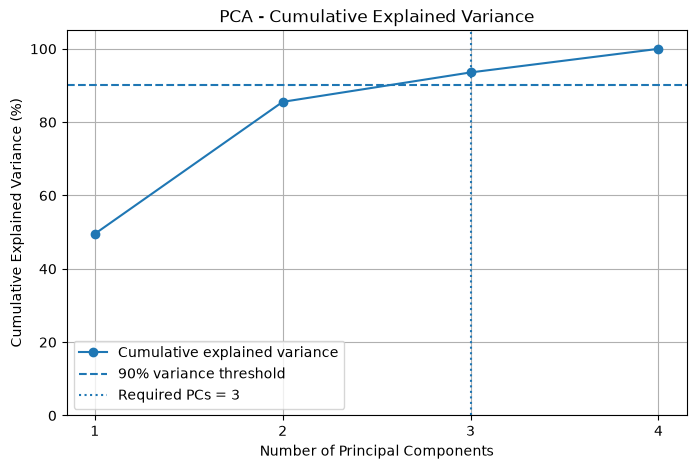

In [14]:
# --- PCA Scaffolding (after you have a normalized DataFrame) ---
# Assumptions:
# 1) You already loaded housing_data.csv into df
# 2) You created normalized columns OR a normalized DataFrame (e.g., df_norm)
#
# If you normalized in-place, you can build df_norm by selecting only the normalized feature columns.

import pandas as pd
import numpy as np

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


# ---- Step A: Choose target and feature columns ----
candidate_features = [
    "Area_sqft_norm",
    "Num_Bedrooms_norm",
    "Num_Bathrooms_norm",
    "Lot_Size_norm"
]

# Create the feature matrix using normalized values
X_pca = df_norm[candidate_features].copy()

# Keep the original Price column separately
# It will be used by Person 3 for correlation analysis
y_price = df_norm["Price"]

print("Features selected for PCA:")
print(candidate_features)

print("\nPCA input shape:")
print(X_pca.shape)

# ---- Step B: Ensure scaling appropriate for PCA ----


print("\nNormalized feature ranges:")
display(X_pca.agg(["min", "max"]))

# Verify that the selected features contain valid values
assert np.isfinite(X_pca.to_numpy()).all(), (
    "PCA input contains missing or infinite values."
)

print("\nAll selected features contain valid numerical values.")


# ---- Step C: Fit PCA ----

# Create PCA object
# PCA() initially keeps all available components
pca = PCA()

# Fit PCA and transform the normalized data
pca_scores = pca.fit_transform(X_pca)

# Create names for the principal components
pc_names = [
    f"PC{i}" for i in range(1, pca.n_components_ + 1)
]

# Store the transformed data in a DataFrame
pca_df = pd.DataFrame(
    pca_scores,
    columns=pc_names,
    index=df_norm.index
)

print("\nNumber of PCA components:")
print(pca.n_components_)

print("\nFirst five transformed rows:")
display(pca_df.head())

# ---- Step D: Variance explained ----

# Calculate explained variance for each component
explained_variance = pca.explained_variance_ratio_

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# Create a table to display the results
variance_df = pd.DataFrame({
    "Principal Component": pc_names,
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

print("\nExplained Variance Table:")
display(variance_df.round(2))

# Find the minimum number of components
# needed to explain at least 90% variance
n_components_90 = (
    np.searchsorted(cumulative_variance, 0.90) + 1
)

print(
    f"\nNumber of PCs needed for at least 90% variance: "
    f"{n_components_90}"
)

print(
    f"Cumulative explained variance: "
    f"{cumulative_variance[n_components_90 - 1] * 100:.2f}%"
)


# Visualize cumulative explained variance

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o",
    label="Cumulative explained variance"
)

# Add a reference line at 90%
plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance threshold"
)

# Mark the minimum number of required components
plt.axvline(
    x=n_components_90,
    linestyle=":",
    label=f"Required PCs = {n_components_90}"
)

plt.xticks(range(1, len(cumulative_variance) + 1))

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Cumulative Explained Variance")

plt.ylim(0, 105)
plt.grid(True)
plt.legend()

plt.show()

# ---- Step E: Loadings (feature contributions to PCs) ----

# ---- Step F: Relate PCs to the target (simple correlation) ----


### PCA Implementation and Explained Variance

**Objective:** Apply Principal Component Analysis (PCA) to the normalized housing data and determine the minimum number of components needed to explain at least 90% of the variance.

**Feature Selection:** We selected four normalized housing features: `Area_sqft_norm`, `Num_Bedrooms_norm`, `Num_Bathrooms_norm`, and `Lot_Size_norm`.

We excluded `House_ID` because it is an identifier. We excluded `Price` and `Price_norm` because they represent the target variable. We also excluded `Year_Built` because it was not included in the original normalization step.

**PCA Implementation:** We applied PCA to the normalized feature matrix and calculated the explained variance ratio and cumulative explained variance.

**Results:** The minimum number of principal components required to explain at least 90% of the variance is **3 PCs**, which together explain **93.56%** of the total variance.

**Conclusion:** Three principal components preserve most of the variation in the four selected housing features. This means we can represent the data using three components instead of four original features while retaining 93.56% of their variance. However, high explained variance does not necessarily mean the components are strongly related to house prices.

### 🔎 Talking Points #2 — [Replace "Talking Point #n" with your insights]

- **Talking point #1**: PCA follows variance, so an unscaled `Price` or `Lot_Size` would take over PC1 and the components would just reflect units. Scaling first lets the components show structure.
- **Talking point #2**: it takes all 4 components to reach 90% variance because the housing features are nearly uncorrelated, so PCA cannot reduce the dimensions without losing information.
- **Talking point #3**: PCA never sees `Price`, and no component correlates with it (|r| < 0.03). Predicting price needs a supervised model, and PCA is only useful for exploring structure or compressing data.

# 📤 How to Submit the Assignment

Follow these instructions carefully to ensure your team submits a complete and well-organized assignment.

## Step 1: Get the Starter Repository

1. Clone the GitHub repository provided by the instructor.
2. Keep the **original repository name**. Do **not** rename the repository.

## Step 2: Complete the Workshop

3. Create **one shared Jupyter Notebook** for the entire team to work on.
4. At the top of **`MinMax_Normalization_Workshop.ipynb`**, clearly include:
   - Team Number
   - Full Name of each team member
5. Complete **all coding tasks, analyses, and written answers** in the same notebook.
6. Make sure all notebook cells execute successfully before submission.

## Step 3: Update the Project Documentation

7. Replace the existing **`README.md`** file with a new version that:
   - Introduces your team
   - Explains the purpose of the workshop
   - Describes the work you completed
   - Summarizes your findings and conclusions
   - Can be used as the visual aid for your team's **5-minute presentation**

## Step 4: Review Project Dependencies

8. Review the project's Python dependencies and decide whether the **`requirements.txt`** file needs to be updated.
   - If you installed additional packages, regenerate or update the file.
   - If no new dependencies were added, no changes may be necessary.

## Step 5: Publish Your Work

9. Push the completed repository to your own GitHub account.
10. Verify that all files have been uploaded correctly and that the repository is publicly accessible if required by the instructor.

---

## ✅ Submission Checklist

Before submitting, confirm that the following items are complete:

- [ ] Repository name has not been changed
- [ ] `MinMax_Normalization_Workshop.ipynb` contains all required work
- [ ] Team number and team member names appear at the top of the notebook
- [ ] All questions have been answered
- [ ] All code runs successfully
- [ ] `README.md` has been replaced with a project summary
- [ ] README can support a 5-minute presentation
- [ ] `requirements.txt` has been reviewed and updated if necessary
- [ ] Repository has been pushed to your GitHub account
- [ ] Final work has been reviewed by all team members

> **Important:** Submit a repository that is clean, complete, and easy to understand. The notebook and README should clearly demonstrate your team's work, findings, and understanding of Min-Max Normalization.